# Selección y evaluación temporal de modelos

Comparamos procedimientos de aprendizaje con **tres folds exteriores**. Parámetros, variables, iteraciones y umbral se eligen con datos anteriores a cada evaluación. El período 621–730 queda fuera de este notebook.

In [1]:
from pathlib import Path
import os
import json
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd() if (Path.cwd() / "review_config.yml").exists() else Path.cwd().parent
os.chdir(ROOT)
from ferreyros_propension.review import read_config
config = read_config()
OUTPUT = ROOT / config["output"]
assert config["development_end"] == 620

def show_metrics(frame):
    formats = {}
    for column in frame:
        if column.startswith(("precision", "recall", "f1", "balance")):
            formats[column] = "{:.1%}"
        elif column.startswith(("auc", "ap", "logloss")):
            formats[column] = "{:.3f}"
    display(frame.style.format(formats, na_rep="—"))


C:\Users\errop\OneDrive\Documentos\Projects\ferreyros-propension\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Resultado de la revisión

La síntesis distingue resultados observados, mejoras sustentadas y limitaciones. El ranking de desarrollo es exploratorio: no confirma un ganador en datos nuevos.

In [2]:
display(Markdown((OUTPUT / "RESULTS.md").read_text(encoding="utf-8")))

# Resultado: no se consiguió una mejora del equilibrio frente al histórico

La revisión implementó y ejecutó el protocolo anidado, las cuatro familias clásicas, TabM/MLP, nuevas variables, ablaciones, semillas, calibración y ensambles. **Ningún procedimiento completo alcanza más de 60% en precisión y recall simultáneamente en los tres folds.** No se evaluó el test.

## Comparación principal

Promedios simples de las tres validaciones exteriores. El criterio congelado es la media de min(precisión, recall) calculado dentro de cada fold; no equivale al mínimo de las dos medias.

| Procedimiento | Precisión | Recall | F1 | AUC | Criterio de equilibrio |
|---|---:|---:|---:|---:|---:|
| Histórico | 50.0% | 50.5% | 50.2% | 0.724 | 49.3% |
| LightGBM de referencia | 52.4% | 53.8% | 52.8% | 0.756 | 49.3% |
| XGBoost: mejor familia nueva observada | 50.0% | 57.6% | 53.1% | 0.756 | 48.6% |

El histórico conserva el primer puesto según el criterio pactado. La diferencia frente a la referencia es mínima y no establece superioridad futura. XGBoost mejora F1 y AUC frente al histórico, pero su desequilibrio en el segundo fold impide declarar cumplido el objetivo. No se cambia el criterio después de observar este resultado.

La referencia utiliza los hiperparámetros del LightGBM anterior bajo el preprocesamiento y ajuste interno de umbral corregidos. Es una comparación controlada de esa configuración, no una reproducción literal de una antigua cifra obtenida con otro procedimiento.

## XGBoost: entrenamiento y validación por fold

| Fold | Train / validación | Datos | Visitas | Precisión | Recall | F1 | AUC |
|---|---|---|---:|---:|---:|---:|---:|
| 1 | 1–296 / 297–404 | Train | 25,754 | 52.6% | 47.6% | 50.0% | 0.753 |
| 1 | 1–296 / 297–404 | Validación | 8,409 | 54.2% | 50.2% | 52.1% | 0.741 |
| 2 | 1–404 / 405–512 | Train | 34,163 | 51.4% | 56.9% | 54.0% | 0.775 |
| 2 | 1–404 / 405–512 | Validación | 8,364 | 46.6% | 65.0% | 54.3% | 0.774 |
| 3 | 1–512 / 513–620 | Train | 42,527 | 50.4% | 58.5% | 54.1% | 0.775 |
| 3 | 1–512 / 513–620 | Validación | 8,029 | 49.1% | 57.6% | 53.0% | 0.754 |

Train describe el ajuste sobre sus propias visitas; validación ocurre después, con modelo y umbral fijos y el historial actualizado según el contrato. Las brechas de AUC son moderadas; esto no demuestra ausencia de sobreajuste. El problema también incluye transferencia del umbral y capacidad predictiva insuficiente para la meta exigida.

## Qué indican las comprobaciones

- **El historial domina la señal.** Las permutaciones y las doce ablaciones no muestran una mejora grande y estable al añadir perfil, ofertas y nuevas tendencias. Las importancias son descriptivas y pueden ocultar redundancia.
- **El umbral pierde equilibrio.** En el segundo fold, XGBoost obtiene precisión 46,6% y recall 65,0%. Un diagnóstico posterior sobre su curva fija alcanza un equilibrio máximo de 54,7%; no llega a 60/60. Ese valor usa respuestas exteriores, es optimista y no se utiliza como umbral ni resultado del modelo.
- **No basta con mover el umbral de estos modelos.** La referencia y XGBoost no tienen ningún punto 60/60 en sus curvas exteriores observadas. Esto limita esas predicciones concretas; no prueba un límite irrebatible de los datos o de otros modelos.
- **Más complejidad no aportó una mejora defendible.** El blend neuronal/árboles combina probabilidades muy correlacionadas (0,95–0,98) y no supera el criterio principal. La calibración y el ajuste con tendencia previa de tienda tampoco resuelven el problema.
- **Sí hay mejora en otras propiedades.** XGBoost mejora F1 y AUC frente al histórico en los tres folds; los intervalos descriptivos de bootstrap por cliente son positivos para esas diferencias. No corrigen dependencia tienda/día ni la selección reiterada del proyecto.

## Trabajo efectivo y cobertura

- 370 pruebas Optuna completas en estudios principales: 310 clásicas y 60 neuronales; las redes completaron 20 por corte.
- 8 variantes neuronales adicionales de capacidad. Algunas familias clásicas terminaron por presupuesto antes de sus 40 pruebas objetivo; no se presenta la búsqueda como exhaustiva.
- 2,382 ajustes contabilizados: 2,314 principales, 60 diagnósticos y 8 del piloto GPU. Los ajustes clásicos se infieren de las trazas; los neuronales se cuentan mediante registros. Se excluyen pruebas sintéticas y la prueba de memorización pequeña.
- 15,721 épocas neuronales ejecutadas y registradas, contando búsquedas, reajustes y diagnósticos incluidos en el inventario.
- Cierre observado de la sesión de entrenamiento: 107.9 minutos, dentro de los 120 autorizados. Incluye trabajos solapados, coordinación y pausas; no es suma de tiempos por modelo ni tiempo activo continuo de GPU. El informe y la verificación posteriores no entrenan modelos.
- 23 pruebas del código aprobadas y revisión estática sin incidencias. EDA y notebook de resultados ejecutados; el último comprueba que el scoring reproduce predicciones guardadas.

## Recomendación

Conservar el histórico como referencia operativa para el objetivo de equilibrio y mantener el LightGBM de referencia y XGBoost como alternativas probabilísticas documentadas. No añadir un ensamble al flujo final ni sustituir automáticamente el artefacto vigente por una mejora incierta. Antes de otra búsqueda, concretar el coste de falsas alarmas y compras omitidas, revisar el punto real de intervención y obtener señales adicionales disponibles antes de la visita o datos nuevos para confirmar resultados. No hay evidencia para prometer 60/60 con más pruebas del mismo tipo.

Los períodos de desarrollo ya se examinaron repetidamente. El test 621–730, consultado históricamente, permaneció fuera de este encargo; una confirmación plenamente independiente requiere datos nuevos. No se publicaron cambios ni se generaron PDF, slides o TXT finales.

**Detalle:** `metrics.csv`, `leaderboard.csv`, `gaps.csv`, `bootstrap_vs_historical.csv`, `threshold_transfer_diagnostic.csv`, `experiment_inventory.csv` y `runtime_summary.json`. Auditoría: `AUDIT.md`; variables: `FEATURES.md`; metodología y skills: `PROTOCOL.md`; errores: `DIAGNOSTICS.md` y `LEADER_EXPLANATION.md`.


## Protocolo congelado

La selección maximiza el promedio por fold de **min(precisión, recall)**; desempata F1 y luego menor log loss. Se aspira a superar 60% en ambas métricas, sin garantizarlo. Aprender probabilidades con log loss es distinto de seleccionar modelos o umbral.

In [3]:
folds = pd.DataFrame([
    {"Fold": number, "Train": f"Días 1–{cut}", "Validación": f"Días {cut + 1}–{end}"}
    for number, (cut, end) in enumerate(config["outer_folds"], 1)
])
display(folds.set_index("Fold"))
splits = pd.read_csv(OUTPUT / "splits.csv")
display(splits.loc[splits.split.isin(["train", "validation"]),
                  ["outer_cut", "split", "visits", "customers", "purchase_rate"]]
        .rename(columns={"outer_cut": "Fin de train", "split": "Datos", "visits": "Visitas",
                         "customers": "Clientes", "purchase_rate": "Tasa de compra"})
        .style.format({"Tasa de compra": "{:.1%}"}))
display(Markdown("Detalle de folds internos y ventanas de parada: `outputs/review_v1/splits.csv`."))

,Train,Validación
Fold,,
1,Días 1–296,Días 297–404
2,Días 1–404,Días 405–512
3,Días 1–512,Días 513–620


,Fin de train,Datos,Visitas,Clientes,Tasa de compra
0,296,train,25754,500,23.8%
1,296,validation,8409,500,26.8%
11,404,train,34163,500,24.5%
12,404,validation,8364,500,25.3%
22,512,train,42527,500,24.7%
23,512,validation,8029,500,26.1%


Detalle de folds internos y ventanas de parada: `outputs/review_v1/splits.csv`.

## Variables conocidas antes de la visita

Historial individual, perfil y ofertas se separan para comprobar su aporte. Las señales nuevas de tienda usan solo días anteriores. El conjunto de referencia reproduce el LightGBM anterior y contiene derivados de ofertas; no se interpreta como “solo historial”. El [diccionario de los 106 predictores](../outputs/review_v1/FEATURES.md) documenta fórmulas, ventanas, disponibilidad y supuestos.

In [4]:
manifest = json.loads((OUTPUT / "manifest.json").read_text(encoding="utf-8"))
display(pd.DataFrame([{"Grupo de variables": name, "Predictores": len(columns)}
                      for name, columns in manifest["features"].items()]))

,Grupo de variables,Predictores
0,history,61
1,history_offers,82
2,all,88
3,enhanced,106
4,reference,72


## Ejecución reproducible

Los estudios tienen almacenamiento persistente y huellas de datos, configuración y código. Para repetir, ejecutar `python run_review.py audit`, `python run_review.py classical` y `python run_review.py neural`. Los resultados de esta revisión y la síntesis se leen a continuación; abrir el notebook no lanza búsquedas costosas.

In [5]:
inventory = json.loads((OUTPUT / "inventory_summary.json").read_text(encoding="utf-8"))
inventory_items = {
    "Pruebas Optuna completas (estudios principales)": "main_complete_optuna_trials",
    "Variantes manuales principales": "main_manual_variants",
    "Entrenamientos principales contabilizados": "main_training_fits",
    "Entrenamientos diagnósticos contabilizados": "diagnostic_training_fits",
    "Épocas neuronales ejecutadas y registradas": "neural_executed_epochs_logged",
    "Pruebas fallidas registradas": "failed_trials_captured",
}
display(pd.DataFrame([{"Indicador": label, "Cantidad": inventory[key]}
                      for label, key in inventory_items.items()]))
display(Markdown("Pruebas, entrenamientos y épocas son unidades distintas. Metodología y contadores completos: "
                 "`outputs/review_v1/README.md`, `experiment_inventory.csv` e `inventory_summary.json`."))

,Indicador,Cantidad
0,Pruebas Optuna completas (estudios principales),370
1,Variantes manuales principales,8
2,Entrenamientos principales contabilizados,2314
3,Entrenamientos diagnósticos contabilizados,60
4,Épocas neuronales ejecutadas y registradas,15721
5,Pruebas fallidas registradas,0


Pruebas, entrenamientos y épocas son unidades distintas. Metodología y contadores completos: `outputs/review_v1/README.md`, `experiment_inventory.csv` e `inventory_summary.json`.

## Cada fold: entrenamiento frente a validación

Las métricas de train diagnostican el ajuste; las exteriores describen la evaluación del procedimiento completo. Un recall mayor en validación no prueba ausencia de sobreajuste.

In [6]:
metrics = pd.read_csv(OUTPUT / "metrics.csv")
leaderboard = pd.read_csv(OUTPUT / "leaderboard.csv")
leaders = leaderboard.loc[leaderboard.complete, "model"].head(5).tolist()
shown = list(dict.fromkeys(leaders + ["historical", "reference"]))
for number, (cut, end) in enumerate(config["outer_folds"], 1):
    display(Markdown(f"**Fold {number} · Train: días 1–{cut} · Validación: días {cut + 1}–{end}**"))
    table = metrics.loc[metrics.model.isin(shown) & metrics.cut.eq(cut),
                        ["model", "split", "n", "precision", "recall", "f1", "auc"]].copy()
    table["split"] = table.split.map({"train": "Train", "validation": "Validación"})
    show_metrics(table.sort_values(["model", "split"]).rename(
        columns={"model": "Modelo", "split": "Datos", "n": "Visitas"}))
display(Markdown("Se limita la vista a cinco procedimientos completos y las dos referencias. "
                 "AP, log loss, umbrales y todos los candidatos: `outputs/review_v1/metrics.csv`."))

**Fold 1 · Train: días 1–296 · Validación: días 297–404**

,Modelo,Datos,Visitas,precision,recall,f1,auc
30,catboost,Train,25754,54.8%,42.1%,47.6%,0.742
31,catboost,Validación,8409,58.7%,43.8%,50.2%,0.738
48,chronological_weighted,Train,25754,51.8%,47.5%,49.6%,0.744
49,chronological_weighted,Validación,8409,57.3%,45.6%,50.8%,0.738
60,historical,Train,25754,49.4%,44.1%,46.6%,0.709
61,historical,Validación,8409,51.5%,49.4%,50.4%,0.720
96,reference,Train,25754,53.5%,47.0%,50.1%,0.757
97,reference,Validación,8409,55.6%,46.3%,50.5%,0.741
126,xgboost,Train,25754,52.6%,47.6%,50.0%,0.753
127,xgboost,Validación,8409,54.2%,50.2%,52.1%,0.741


**Fold 2 · Train: días 1–404 · Validación: días 405–512**

,Modelo,Datos,Visitas,precision,recall,f1,auc
32,catboost,Train,34163,49.8%,54.3%,52.0%,0.757
33,catboost,Validación,8364,51.2%,59.0%,54.8%,0.772
50,chronological_weighted,Train,34163,50.2%,55.2%,52.6%,0.762
51,chronological_weighted,Validación,8364,50.6%,58.9%,54.4%,0.774
62,historical,Train,34163,49.4%,47.1%,48.2%,0.713
63,historical,Validación,8364,50.9%,52.9%,51.9%,0.743
98,reference,Train,34163,51.3%,51.9%,51.6%,0.757
99,reference,Validación,8364,50.9%,59.0%,54.6%,0.777
128,xgboost,Train,34163,51.4%,56.9%,54.0%,0.775
129,xgboost,Validación,8364,46.6%,65.0%,54.3%,0.774


**Fold 3 · Train: días 1–512 · Validación: días 513–620**

,Modelo,Datos,Visitas,precision,recall,f1,auc
34,catboost,Train,42527,51.0%,53.3%,52.1%,0.759
35,catboost,Validación,8029,50.0%,57.2%,53.3%,0.748
52,chronological_weighted,Train,42527,47.1%,63.3%,54.0%,0.770
53,chronological_weighted,Validación,8029,48.0%,61.8%,54.0%,0.749
64,historical,Train,42527,49.5%,48.8%,49.1%,0.719
65,historical,Validación,8029,47.7%,49.2%,48.4%,0.707
100,reference,Train,42527,51.3%,53.1%,52.2%,0.762
101,reference,Validación,8029,50.7%,56.1%,53.2%,0.751
130,xgboost,Train,42527,50.4%,58.5%,54.1%,0.775
131,xgboost,Validación,8029,49.1%,57.6%,53.0%,0.754


Se limita la vista a cinco procedimientos completos y las dos referencias. AP, log loss, umbrales y todos los candidatos: `outputs/review_v1/metrics.csv`.

## Promedio y estabilidad

Se muestran todos los folds y el resumen; el promedio no debe ocultar una caída. Una pequeña diferencia sin evidencia suficiente no constituye una mejora concluyente.

In [7]:
show_metrics(leaderboard.loc[leaderboard.model.isin(shown),
    ["model", "folds", "precision_mean", "recall_mean", "f1_mean", "auc_mean",
     "balance_mean", "balance_std", "folds_60_60"]])
comparison_model = next((name for name in leaders if name not in {"historical", "constant"}), "reference")
gaps = pd.read_csv(OUTPUT / "gaps.csv")
display(Markdown(f"**Brecha train menos validación del candidato aprendido destacado: `{comparison_model}`.** "
                 "Una brecha pequeña no garantiza ausencia de sobreajuste."))
show_metrics(gaps.loc[gaps.model.eq(comparison_model),
    ["cut", "precision_gap", "recall_gap", "f1_gap", "auc_gap"]])
display(Markdown("Resumen y brechas completos: `leaderboard.csv` y `gaps.csv` en `outputs/review_v1/`."))

,model,folds,precision_mean,recall_mean,f1_mean,auc_mean,balance_mean,balance_std,folds_60_60
0,historical,3,50.0%,50.5%,50.2%,0.724,49.3%,1.6%,0
1,reference,3,52.4%,53.8%,52.8%,0.756,49.3%,2.6%,0
2,xgboost,3,50.0%,57.6%,53.1%,0.756,48.6%,1.8%,0
3,catboost,3,53.3%,53.3%,52.8%,0.753,48.3%,4.0%,0
4,chronological_weighted,3,52.0%,55.4%,53.1%,0.753,48.1%,2.5%,0


**Brecha train menos validación del candidato aprendido destacado: `reference`.** Una brecha pequeña no garantiza ausencia de sobreajuste.

,cut,precision_gap,recall_gap,f1_gap,auc_gap
48,296,-2.1%,0.8%,-0.5%,0.016
49,404,0.5%,-7.1%,-3.0%,-0.020
50,512,0.6%,-2.9%,-1.0%,0.011


Resumen y brechas completos: `leaderboard.csv` y `gaps.csv` en `outputs/review_v1/`.

## Comparaciones visuales y aprendizaje neuronal

La validación usada para parar la red es **interna al entrenamiento**; no debe confundirse con la validación exterior de las tablas.

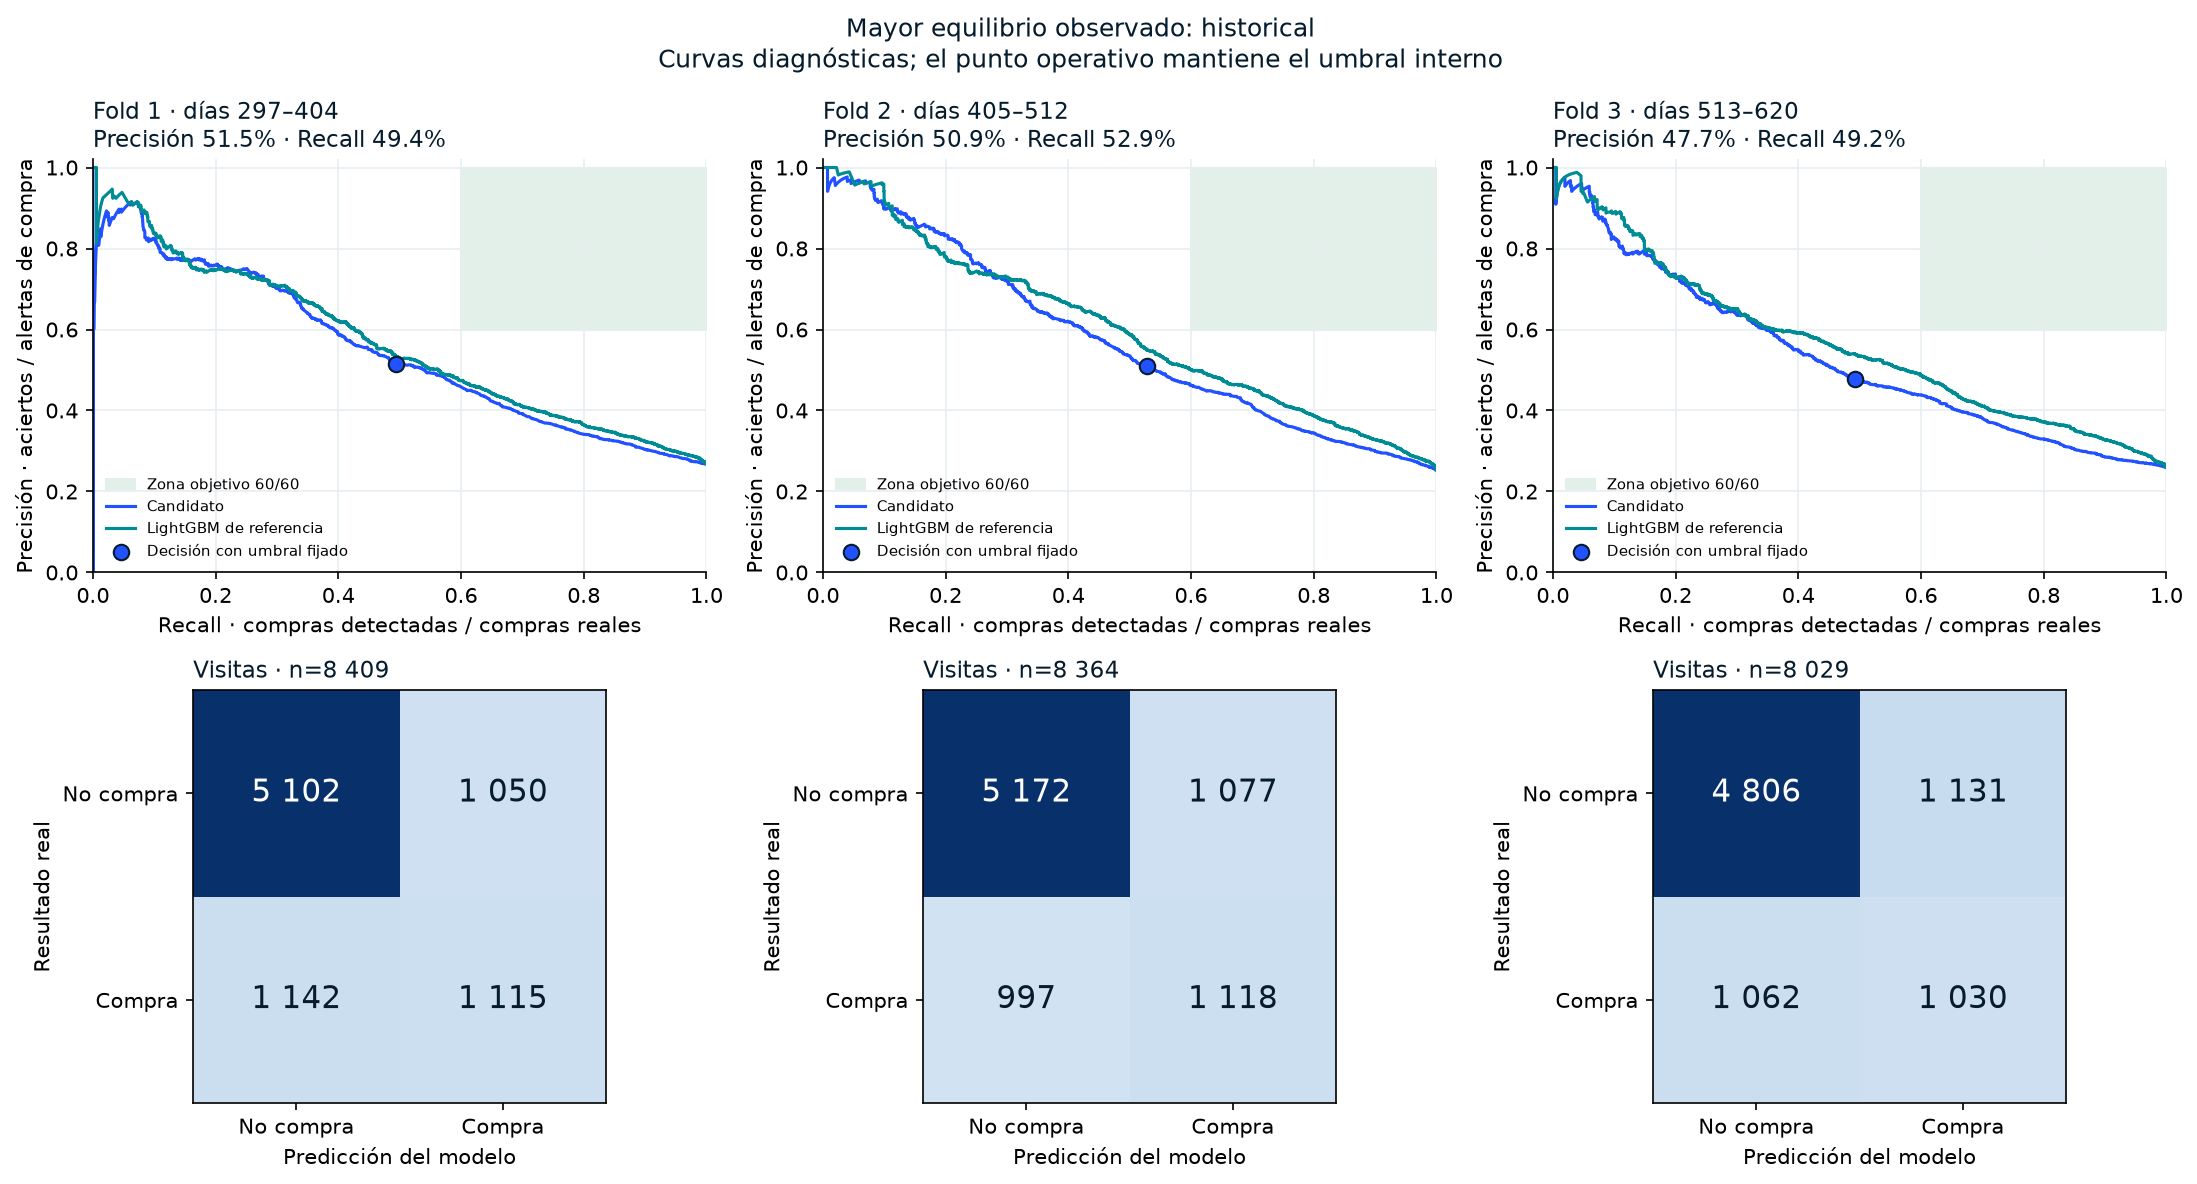

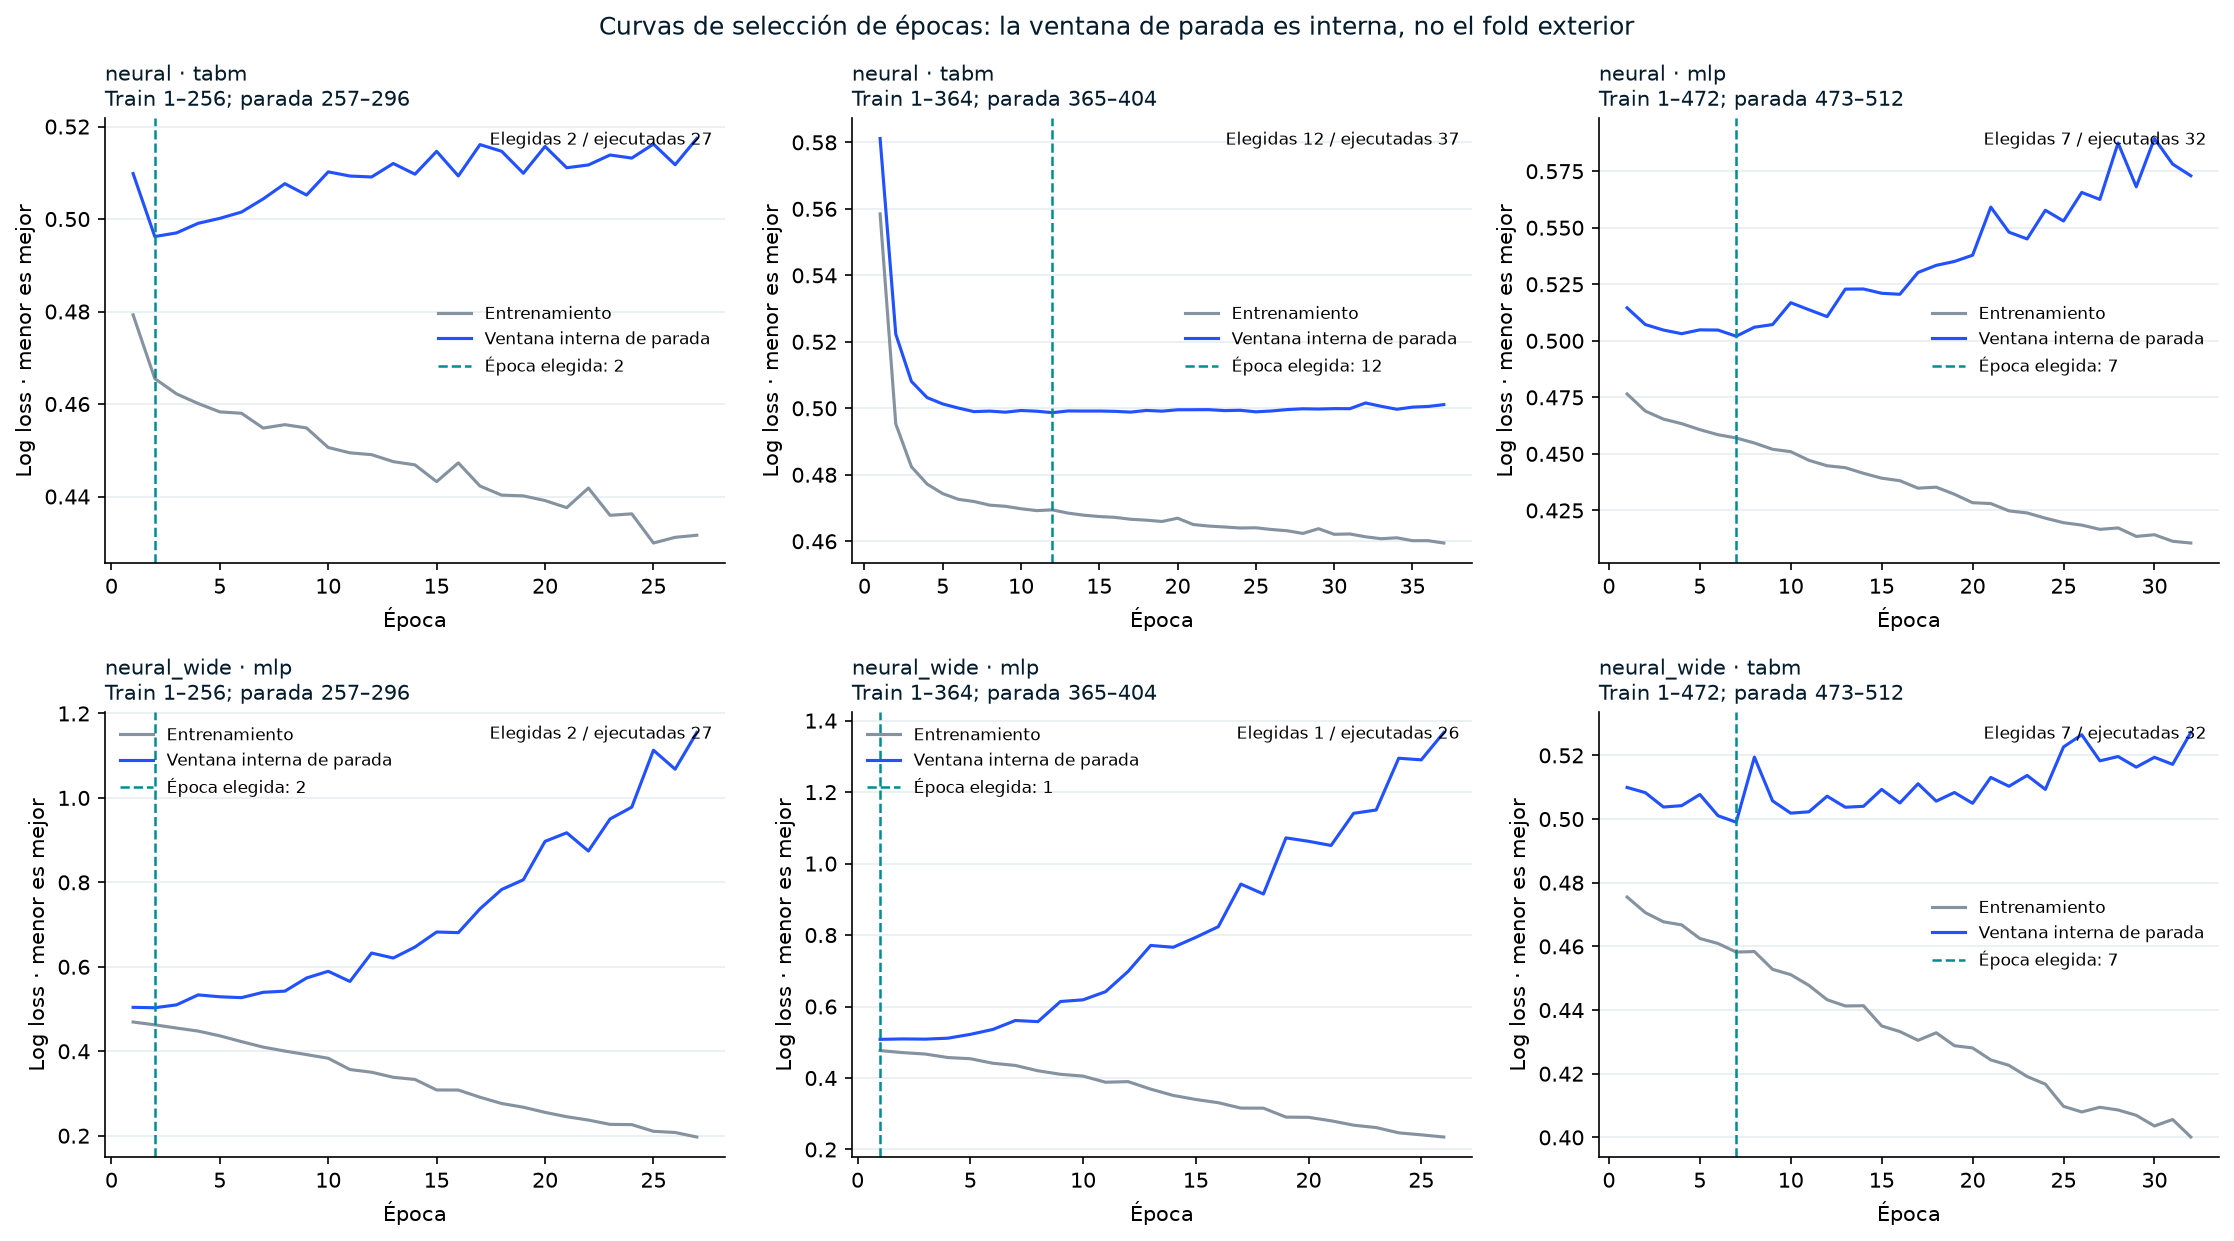

Curvas PR exteriores: diagnóstico, no ajuste de un nuevo umbral. Las figuras completas de todos los modelos por fold están en `outputs/review_v1/figures/`.

In [8]:
for name in ["selected_candidate_diagnostics.png", "neural_curves.png"]:
    display(Image(filename=str(OUTPUT / "figures" / name)))
display(Markdown("Curvas PR exteriores: diagnóstico, no ajuste de un nuevo umbral. "
                 "Las figuras completas de todos los modelos por fold están en `outputs/review_v1/figures/`."))

## Incertidumbre y errores

El bootstrap agrupa por cliente para no tratar visitas repetidas como personas independientes. Los segmentos muestran soporte, aciertos y errores; las asociaciones no identifican causas por sí solas.

In [9]:
bootstrap = pd.read_csv(OUTPUT / "bootstrap_vs_historical.csv")
display(Markdown(f"**Diferencias de `{comparison_model}` frente al histórico: F1 y AUC.** "
                 "Intervalos de 95% agrupados por cliente; no corrigen todas las dependencias tienda/día ni la selección repetida."))
display(bootstrap.loc[bootstrap.model.eq(comparison_model) & bootstrap.metric.isin(["f1", "auc"]),
                      ["cut", "metric", "delta", "ci_low", "ci_high"]]
        .style.format({"delta": "{:+.3f}", "ci_low": "{:+.3f}", "ci_high": "{:+.3f}"}))
errors = pd.read_csv(OUTPUT / "error_segments.csv")
last_cut = config["outer_folds"][-1][0]
display(Markdown("**Último fold: errores por historial, solo segmentos con soporte suficiente.** "
                 "FP son falsas alarmas; FN son compras no detectadas. Las dimensiones se superponen y no deben sumarse."))
subset = errors.loc[errors.model.eq(comparison_model) & errors.cut.eq(last_cut)
                    & errors.dimension.isin(["recencia", "frecuencia"]) & ~errors.small_support]
show_metrics(subset[["dimension", "segment", "n", "customers", "precision", "recall", "f1", "fp", "fn"]]
             .sort_values(["dimension", "n"], ascending=[True, False]))
display(Markdown("Resultados completos: `bootstrap_vs_historical.csv`, `error_segments.csv` "
                 "y `DIAGNOSTICS.md` en `outputs/review_v1/`."))

**Diferencias de `reference` frente al histórico: F1 y AUC.** Intervalos de 95% agrupados por cliente; no corrigen todas las dependencias tienda/día ni la selección repetida.

,cut,metric,delta,ci_low,ci_high
62,296,f1,+0.001,-0.014,+0.020
63,296,auc,+0.021,+0.012,+0.033
146,404,f1,+0.027,+0.014,+0.044
147,404,auc,+0.034,+0.025,+0.044
230,512,f1,+0.048,+0.032,+0.068
231,512,auc,+0.044,+0.034,+0.055


**Último fold: errores por historial, solo segmentos con soporte suficiente.** FP son falsas alarmas; FN son compras no detectadas. Las dimensiones se superponen y no deben sumarse.

,dimension,segment,n,customers,precision,recall,f1,fp,fn
1133,frecuencia,mas30,8029,500,50.7%,56.1%,53.2%,1141,919
1139,recencia,8a30,3145,451,46.9%,55.7%,50.9%,608,428
1140,recencia,hasta7,1698,391,56.4%,80.2%,66.3%,453,145
1141,recencia,mas60,1657,286,45.0%,5.1%,9.1%,11,168
1138,recencia,31a60,1529,377,36.1%,18.0%,24.0%,69,178


Resultados completos: `bootstrap_vs_historical.csv`, `error_segments.csv` y `DIAGNOSTICS.md` en `outputs/review_v1/`.

## Coste real del entrenamiento

Los tiempos por tarea pueden solaparse. No se suman como tiempo de espera. La parada temprana tampoco equivale a demostrar convergencia.

In [10]:
times = pd.read_csv(OUTPUT / "times.csv")
cost = times.loc[times.model.isin(shown)].groupby("model", sort=False).agg(
    tareas=("cut", "size"), segundos_por_tarea_promedio=("seconds", "mean"))
display(cost.round(1))
display(Markdown("Estos son tiempos medios por tarea, no tiempo total de espera. "
                 "Tiempos completos y reloj de las ejecuciones: `times.csv` y `runtime_summary.json` "
                 "en `outputs/review_v1/`."))

,tareas,segundos_por_tarea_promedio
model,,
catboost,3,1320.7
chronological_weighted,3,483.9
historical,3,3.2
reference,3,8.3
xgboost,3,399.1


Estos son tiempos medios por tarea, no tiempo total de espera. Tiempos completos y reloj de las ejecuciones: `times.csv` y `runtime_summary.json` en `outputs/review_v1/`.

## Comprobar el uso del modelo

Demostración con el LightGBM de referencia entrenado hasta el día 512, puntuando el día 620 de desarrollo. No se usa el test. El constructor ignora el resultado actual y emplea el historial anterior de toda la tienda.

In [11]:
import joblib
import numpy as np
from ferreyros_propension.review import development_data, score_review_visits
raw = development_data(config)
bundle = joblib.load(OUTPUT / "reference_512/model.joblib")
scored = score_review_visits(bundle, raw.loc[raw.dia_visita.lt(620)], raw.loc[raw.dia_visita.eq(620)])
expected = pd.read_csv(OUTPUT / "reference_512/validation_predictions.csv")
paired = scored.merge(expected.loc[expected.dia_visita.eq(620)], on=["id", "dia_visita"], validate="one_to_one")
assert np.allclose(paired.probability, paired.p, rtol=0, atol=1e-10)
display(pd.DataFrame({"visitas_puntuadas": [len(scored)], "compras_predichas": [int(scored.prediction.sum())], "probabilidad_media": [scored.probability.mean()]}))

,visitas_puntuadas,compras_predichas,probabilidad_media
0,91,32,0.286842


## Captura de valor y límites

El modelo identifica visitas con propensión elevada; no estima por sí solo el efecto incremental de una promoción. El valor comercial exige costes, márgenes y una prueba controlada de intervención. Indicadores propuestos: precisión/recall al umbral fijado, conversión por grupo, coste por compra incremental y margen incremental. No se inventa ROI sin esos datos.

No se ha ejecutado ni consultado el test durante esta revisión. Como ya se había examinado históricamente, una confirmación plenamente independiente requeriría datos nuevos.